# <font color='#BFD72F' size=6>**0. Imports**</font> <a class="anchor" id="1"></a>

[Back to TOC](#toc)

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from config import (
    PREPROCESSED_DIR,
    RANDOM_SEED,
    WINDOW_SIZE,
    FEATURE_COLS_A,
    FEATURE_COLS_B,
    RESULTS_DIR,
)

from river import (
    compose,
    dummy,
    ensemble,
    forest,          # Adaptive Random Forest
    linear_model,
    metrics,
    naive_bayes,
    optim,
    preprocessing,   # online StandardScaler for the logistic regression
    tree,
)

In [2]:
CITIES = ["Aveiro", "Viseu"]
TARGET_COL = "target_hot"                      # your export names it target_hot, not "target"
REPRESENTATIONS = {"A": list(FEATURE_COLS_A), "B": list(FEATURE_COLS_B)}
CURRENT_VALUE_COLS = {"temperature"}           # target-defining column at time t; adjust to your raw name

with open(PREPROCESSED_DIR / "preproc_meta.json", encoding="utf-8") as f:
    meta = json.load(f)                        # tau_t_hot, warmup_start/end, hot_percentile

# Full timeline (warm-up + evaluation, has a `period` column)
preproc_data = {
    city: pd.read_csv(PREPROCESSED_DIR / f"preproc_{city.lower()}.csv", parse_dates=["time"])
    for city in CITIES
}
# Past-only features + target_hot (evaluation rows only) -> this is what the models replay
stream_data = {
    city: pd.read_csv(PREPROCESSED_DIR / f"stream_{city.lower()}.csv", parse_dates=["time"])
    for city in CITIES
}

# ---- Checks: leakage, chronology, target, common timeline ----
for rep, cols in REPRESENTATIONS.items():
    leaked = CURRENT_VALUE_COLS & set(cols)
    assert not leaked, f"Representation {rep} uses current-time target-defining columns: {leaked}"

for city, df in stream_data.items():
    needed = ["time", TARGET_COL, *REPRESENTATIONS["A"], *REPRESENTATIONS["B"]]
    missing = [c for c in needed if c not in df.columns]
    assert not missing, f"{city}: stream is missing columns {missing}"
    assert df["time"].is_monotonic_increasing, f"{city}: stream is not in chronological order"
    assert df["time"].is_unique, f"{city}: duplicated timestamps"
    assert df[TARGET_COL].isin([0, 1]).all(), f"{city}: target must be 0/1 with no NaN"
    assert df[REPRESENTATIONS["B"]].notna().all().all(), f"{city}: NaN in feature columns"
    pre = preproc_data[city]
    first_eval = pre.loc[pre["period"] == "evaluation", "time"].min()
    assert df["time"].min() >= first_eval, f"{city}: stream starts inside the warm-up period"

assert stream_data["Aveiro"]["time"].equals(stream_data["Viseu"]["time"]), \
    "cities have different evaluation timelines"

# <font color='#BFD72F' size=6>**6. Models**</font> <a class="anchor" id="1"></a>



[Back to TOC](#toc)

### Define River models

In [3]:
ENSEMBLE_SIZE = 10                              # River's default; set to 5 to match the Weekend Challenge
HT_PARAMS = dict(grace_period=50, delta=1e-3, tau=0.10, leaf_prediction="mc")
LOGISTIC_LR = 0.05


def make_hoeffding_tree() -> tree.HoeffdingTreeClassifier:
    return tree.HoeffdingTreeClassifier(**HT_PARAMS)


def make_models(include_baselines=True, include_optional=False,
                n_models=ENSEMBLE_SIZE, seed=RANDOM_SEED):
    """Fresh instances every call (HB 12.7). Same configuration for every city/representation."""
    models = {
        "Gaussian NB": naive_bayes.GaussianNB(),

        "Online Logistic Regression": compose.Pipeline(
            preprocessing.StandardScaler(),     # online scaler: learns from the past only
            linear_model.LogisticRegression(optimizer=optim.SGD(LOGISTIC_LR)),
        ),

        "Hoeffding Tree": make_hoeffding_tree(),

        "Online Bagging": ensemble.BaggingClassifier(
            model=make_hoeffding_tree(), n_models=n_models, seed=seed,
        ),

        "Adaptive Random Forest": forest.ARFClassifier(      # the missing mandatory model
            n_models=n_models, max_features="sqrt", lambda_value=6, seed=seed, **HT_PARAMS,
        ),
    }

    if include_baselines:   # not required; shows whether models beat "predict the previous state"
        models = {
            "Majority class (baseline)": dummy.PriorClassifier(),
            "No-change (baseline)": dummy.NoChangeClassifier(),
            **models,
        }

    if include_optional:    # extensions; they do not replace the five mandatory models
        models["Leveraging Bagging"] = ensemble.LeveragingBaggingClassifier(
            model=make_hoeffding_tree(), n_models=n_models, w=6, seed=seed,
        )
        models["Streaming Random Patches"] = ensemble.SRPClassifier(
            model=make_hoeffding_tree(), n_models=n_models, subspace_size=0.6,
            training_method="patches", lam=6, seed=seed,
        )
    return models


MANDATORY_MODELS = ["Gaussian NB", "Online Logistic Regression", "Hoeffding Tree",
                    "Online Bagging", "Adaptive Random Forest"]

### Prequential online evaluation

Each observation follows the same sequence:

1. Predict the current target.
2. Evaluate the prediction.
3. Update cumulative and rolling metrics.
4. Train the model on the observation.

In [4]:
import importlib.metadata as importlib_metadata
import platform
import time
from collections import deque


class StreamingBinaryEvaluator:
    """Confusion-matrix evaluator with cumulative and sliding-window scores, O(1) per update.

    Positive class = 1 (the heat-stress event). Rows of the matrix are the true class, columns the prediction.
    """

    def __init__(self, window_size: int, initial_label: int | None = None):
        self.window_size = int(window_size)
        self.cm = [[0, 0], [0, 0]]
        self.wcm = [[0, 0], [0, 0]]
        self.window = deque()
        self.cold_starts = 0
        self.prev_label = initial_label       # last label seen BEFORE the current event
        self.nc_correct = 0                   # "repeat the previous label" on the same scored events
        self.nc_n = 0

    def update(self, y_true: int, y_pred: int | None) -> None:
        if y_pred is None:                    # model could not predict yet (cold start)
            self.cold_starts += 1
        else:
            self.cm[y_true][y_pred] += 1
            self.wcm[y_true][y_pred] += 1
            self.window.append((y_true, y_pred))
            if len(self.window) > self.window_size:
                old_true, old_pred = self.window.popleft()
                self.wcm[old_true][old_pred] -= 1
            if self.prev_label is not None:
                self.nc_n += 1
                self.nc_correct += int(self.prev_label == y_true)
        self.prev_label = y_true              # becomes available only after the event

    @staticmethod
    def _scores(cm) -> dict:
        (tn, fp), (fn, tp) = cm
        n = tn + fp + fn + tp

        def f1(tp_, fp_, fn_):
            denom = 2 * tp_ + fp_ + fn_
            return 2 * tp_ / denom if denom else 0.0

        return {
            "accuracy": (tp + tn) / n if n else np.nan,
            "precision": tp / (tp + fp) if (tp + fp) else 0.0,   # event class; 0 if no event predicted
            "recall": tp / (tp + fn) if (tp + fn) else 0.0,      # event class
            "f1": f1(tp, fp, fn),                                # event class
            "macro_f1": (f1(tp, fp, fn) + f1(tn, fn, fp)) / 2 if n else np.nan,
        }

    def snapshot(self) -> dict:
        (tn, fp), (fn, tp) = self.cm
        cumulative = self._scores(self.cm)
        windowed = self._scores(self.wcm)
        no_change_acc = self.nc_correct / self.nc_n if self.nc_n else np.nan
        kappa_t = (
            (cumulative["accuracy"] - no_change_acc) / (1 - no_change_acc)
            if self.nc_n and no_change_acc < 1 else np.nan
        )
        return {
            **cumulative,
            "rolling_macro_f1": windowed["macro_f1"],
            "rolling_accuracy": windowed["accuracy"],
            "kappa_t": kappa_t,                   # > 0: better than repeating the previous label
            "evaluated": tn + fp + fn + tp,
            "cold_starts": self.cold_starts,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn,
        }


ENSEMBLE_TYPES = (
    ensemble.BaggingClassifier,
    ensemble.LeveragingBaggingClassifier,
    ensemble.SRPClassifier,
    forest.ARFClassifier,
)


def model_family(name: str) -> str:
    if "baseline" in name:
        return "Baseline"
    return "Ensemble" if name in {
        "Online Bagging", "Adaptive Random Forest", "Leveraging Bagging", "Streaming Random Patches",
    } else "Single learner"


def _tree_nodes(member) -> int:
    inner = getattr(member, "model", member)      # SRP wraps each tree in a member object
    return int(getattr(inner, "n_nodes", 0) or 0)


def model_complexity(model, n_features: int) -> tuple[int, str]:
    """Supporting evidence only (HB 11.2): structural size, not comparable across families."""
    est = list(model.steps.values())[-1] if isinstance(model, compose.Pipeline) else model
    if isinstance(est, naive_bayes.GaussianNB):
        value = 6 * n_features + 2                # mean, variance, count per class/feature + class counts
        return value, f"{value} statistics"
    if isinstance(est, linear_model.LogisticRegression):
        return n_features + 1, f"{n_features + 1} coefficients"
    if isinstance(est, tree.HoeffdingTreeClassifier):
        return int(est.n_nodes or 0), f"{int(est.n_nodes or 0)} nodes"
    if isinstance(est, ENSEMBLE_TYPES):
        nodes = sum(_tree_nodes(m) for m in est.models)
        return nodes, f"{len(est)} members, {nodes} nodes"
    return 1, "constant rule"


def iter_events(df: pd.DataFrame, feature_cols: list[str]):
    """Yield (time, x, y) in the order of the frame; the caller guarantees chronological order."""
    X = df[feature_cols].to_numpy(dtype=float)
    for time_, row, y in zip(df["time"], X, df[TARGET_COL].to_numpy(dtype=int)):
        yield time_, dict(zip(feature_cols, row.tolist())), int(y)

In [5]:
HISTORY_STRIDE = 24     # store one history row per 24 events (one day of hourly data)


def track_online_performance(
    df_stream: pd.DataFrame,
    feature_cols: list[str],
    df_warmup: pd.DataFrame | None = None,
    models: dict | None = None,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Prequential evaluation: PREDICT -> EVALUATE -> LEARN, one observation at a time.

    - Every model gets fresh instances and exactly the same chronological observations.
    - If df_warmup is given, models learn from it WITHOUT being scored (shared warm-up).
    - Prediction time and update time are measured separately, per model.
    """
    models = make_models() if models is None else models
    initial_label = None

    if df_warmup is not None:
        for _, x, y in iter_events(df_warmup, feature_cols):
            for model in models.values():
                model.learn_one(x, y)
            initial_label = y

    evaluators = {name: StreamingBinaryEvaluator(WINDOW_SIZE, initial_label) for name in models}
    predict_seconds = dict.fromkeys(models, 0.0)
    update_seconds = dict.fromkeys(models, 0.0)
    records = []
    n_events = len(df_stream)

    for i, (time_, x, y) in enumerate(iter_events(df_stream, feature_cols), start=1):
        for name, model in models.items():
            # 1. PREDICT before the label is used
            t0 = time.perf_counter()
            y_pred = model.predict_one(x)
            predict_seconds[name] += time.perf_counter() - t0
            y_pred = None if y_pred is None else int(y_pred)

            # 2. EVALUATE this prediction
            evaluators[name].update(y, y_pred)

            # 3. LEARN only after evaluating
            t1 = time.perf_counter()
            model.learn_one(x, y)
            update_seconds[name] += time.perf_counter() - t1

        if i % HISTORY_STRIDE == 0 or i == n_events:
            record = {"time": time_}
            for name in models:
                snap = evaluators[name].snapshot()
                for metric in ("accuracy", "precision", "recall", "f1", "macro_f1",
                               "rolling_macro_f1", "rolling_accuracy", "kappa_t"):
                    record[f"{name} | {metric}"] = snap[metric]
            records.append(record)

    n_features = len(feature_cols)
    final_scores = []
    for name, model in models.items():
        snap = evaluators[name].snapshot()
        complexity, complexity_label = model_complexity(model, n_features)
        scored = max(1, snap["evaluated"])
        final_scores.append({
            "model": name,
            "family": model_family(name),
            **snap,
            "event_rate": (snap["tp"] + snap["fn"]) / scored,
            "pred_ms_per_event": 1000 * predict_seconds[name] / n_events,
            "update_ms_per_event": 1000 * update_seconds[name] / n_events,
            "complexity": complexity,
            "complexity_label": complexity_label,
        })

    return pd.DataFrame(records), pd.DataFrame(final_scores)

The model is learning to predict the detector's alert state. The detector and the classifier are separate components: the detector defines the target, and the classifier attempts to predict it from earlier weather measurements.

### Run experiments

In [6]:
FIGURES_DIR = RESULTS_DIR / "figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

experiments = {}
results = []

for city, df_stream in stream_data.items():
    for representation, feature_cols in REPRESENTATIONS.items():
        experiment_name = f"{city} - Representation {representation}"
        print(f"Running: {experiment_name} ({len(df_stream):,} events, {len(feature_cols)} features)")

        history, scores = track_online_performance(
            df_stream,
            feature_cols,
            df_warmup=None,       # pass the warm-up frame here once its past-only features are exported
        )

        experiments[experiment_name] = history
        scores.insert(0, "representation", representation)
        scores.insert(0, "city", city)
        results.append(scores)

comparison = pd.concat(results, ignore_index=True)

display(
    comparison[[
        "city", "representation", "model", "accuracy", "macro_f1", "precision", "recall", "f1",
        "kappa_t", "rolling_macro_f1", "cold_starts", "pred_ms_per_event", "update_ms_per_event",
        "complexity_label",
    ]].round(3)
)

metrics_path = RESULTS_DIR / "metrics.csv"
comparison.to_csv(metrics_path, index=False)

configuration = {
    "python": platform.python_version(),
    **{f"version_{p}": importlib_metadata.version(p) for p in ("river", "numpy", "pandas")},
    "random_seed": RANDOM_SEED,
    "target": TARGET_COL,
    "tau_t_hot": meta.get("tau_t_hot"),
    "hot_percentile": meta.get("hot_percentile"),
    "warmup_start": meta.get("warmup_start"),
    "warmup_end": meta.get("warmup_end"),
    "evaluation_start": str(min(df["time"].min() for df in stream_data.values())),
    "evaluation_end": str(max(df["time"].max() for df in stream_data.values())),
    "events_per_city": {c: len(d) for c, d in stream_data.items()},
    "rolling_window_size": WINDOW_SIZE,
    "history_stride": HISTORY_STRIDE,
    "ensemble_size": ENSEMBLE_SIZE,
    "hoeffding_params": HT_PARAMS,
    "logistic_sgd_lr": LOGISTIC_LR,
    "features_A": REPRESENTATIONS["A"],
    "features_B": REPRESENTATIONS["B"],
    "models": list(make_models().keys()),
}
config_path = RESULTS_DIR / "configurations.csv"
pd.DataFrame({"parameter": list(configuration), "value": [str(v) for v in configuration.values()]}).to_csv(
    config_path, index=False
)
print(f"Saved: {metrics_path} and {config_path}")

Running: Aveiro - Representation A (70,104 events, 3 features)
Running: Aveiro - Representation B (70,104 events, 7 features)
Running: Viseu - Representation A (70,104 events, 3 features)


KeyboardInterrupt: 

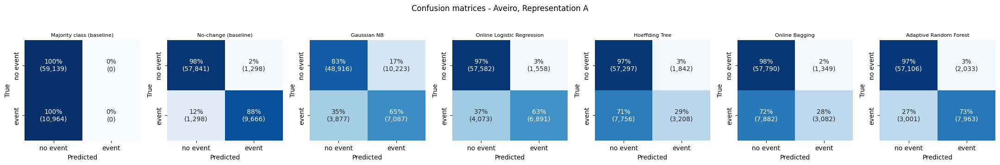

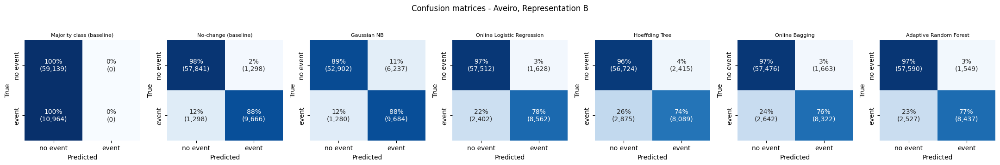

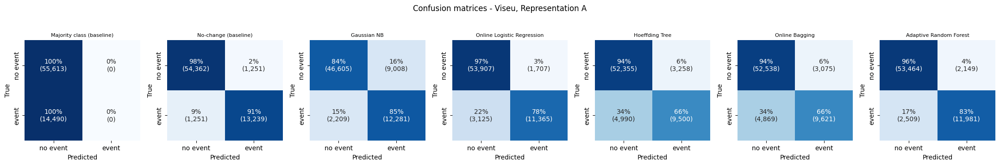

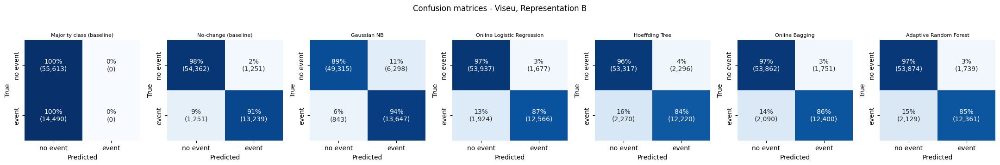

In [ ]:
def plot_confusion_matrices(comparison: pd.DataFrame, city: str, representation: str) -> None:
    subset = comparison[(comparison["city"] == city) & (comparison["representation"] == representation)]
    fig, axes = plt.subplots(1, len(subset), figsize=(3.1 * len(subset), 3.4), squeeze=False)
    for ax, row in zip(axes[0], subset.itertuples(index=False)):
        counts = np.array([[row.tn, row.fp], [row.fn, row.tp]])
        shares = counts / counts.sum(axis=1, keepdims=True).clip(min=1)      # row-normalised: recall view
        annot = np.array([[f"{shares[r, c]:.0%}\n({counts[r, c]:,})" for c in range(2)] for r in range(2)])
        sns.heatmap(shares, annot=annot, fmt="", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    xticklabels=["no event", "event"], yticklabels=["no event", "event"], ax=ax)
        ax.set_title(row.model, fontsize=8)
        ax.set_xlabel("Predicted")
        ax.set_ylabel("True")
    fig.suptitle(f"Confusion matrices - {city}, Representation {representation}", y=1.04)
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / f"confusion_{city.lower()}_{representation}.png", dpi=150, bbox_inches="tight")
    plt.show()


for city in CITIES:
    for representation in REPRESENTATIONS:
        plot_confusion_matrices(comparison, city, representation)

## Conclusions


**Baseline comparison**

All five learned models in each city and representation fall below No-change on accuracy, macro-F1 and event F1. Their precision and recall do not uniformly fall below the baseline: the learned models sometimes have higher precision or recall, depending on the city and representation.

For example, in Aveiro B, Adaptive Random Forest achieves precision 0.845 and recall 0.770, versus 0.882 for both precision and recall under No-change. It detects events with a different balance of false alarms and misses, but does not outperform the persistence baseline overall.

**Interpreting kappa_t**

**Definition:** kappa_t measures how well a model performs compared with the No-change baseline, which predicts that the next observation will have the same label as the previous one. A value of 0 means equal performance, a positive value means the model performs better, and a negative value means it performs worse than this baseline.

The No-change baseline has kappa_t = 0 by construction because it is the reference predictor against which relative agreement is measured. All learned models have negative kappa_t values, ranging from −4.431 to −0.439. Under the metric's intended interpretation, this means they perform worse than repeating the previous label.

Operational implication: The target represents a persistent state more than a newly occurring event. A model can achieve high accuracy by maintaining the previous state, so evaluation should distinguish between predicting whether the next hour is hot and detecting the onset of a new hot event. Negative kappa_t suggests that the learned models are not yet adding value over the persistence rule under this evaluation protocol.


**Representation A vs B (past-only temporal context)**

The difference \(\Delta = B-A\) is positive for every learned model in both cities. Representation B improves macro-F1, event recall and event precision across the board.

- Online Bagging benefits most in both cities: macro-F1 increases by 0.216 in Aveiro and 0.097 in Viseu.

- Hoeffding Tree is the next strongest beneficiary, particularly in Aveiro, where recall increases by 0.445.

- Adaptive Random Forest benefits least, with macro-F1 gains of only 0.027 and 0.017.

Representation B improves the reported event-detection metrics for every learned model. The improvement is particularly substantial for Hoeffding Tree and Online Bagging. However, B still does not beat the No-change baseline on the main aggregate metrics. Temporal context helps the models, but does not establish that they outperform persistence-based prediction.

**Single learners vs ensembles**

Adaptive Random Forest generally improves on the single Hoeffding Tree, particularly in representation A. However, its advantage becomes smaller under representation B, and Online Bagging slightly outperforms it on macro-F1 in Viseu B.

Ensembles incur a clear update-time penalty. Adaptive Random Forest takes approximately 19–22 times as long to update as the Hoeffding Tree in these configurations, although absolute times remain below 0.4 ms per event.

**Is the gain worth the cost?**

Not automatically. In Aveiro B, Adaptive Random Forest improves macro-F1 over Hoeffding Tree by just 0.031, at an extra 0.202 ms per update. Online Bagging offers a smaller update-time penalty than Adaptive Random Forest in Aveiro B while achieving macro-F1 of 0.879 versus 0.886. For continuous monitoring, the marginal predictive gain must justify the added computational and maintenance complexity.

**Predictive quality vs computational cost**

- Highest macro-F1 among learned models: Adaptive Random Forest in Aveiro A (0.859), Aveiro B (0.886) and Viseu A (0.898); Online Logistic Regression in Viseu B (0.921).

- Fastest update among learned models: Online Logistic Regression, at 0.008–0.015 ms per event across the four settings.

- Best overall balance: Online Logistic Regression with representation B. It achieves macro-F1 of 0.888 in Aveiro and 0.921 in Viseu, with update times of 0.011 and 0.015 ms per event, respectively.

If maximum predictive performance is the only priority, Adaptive Random Forest remains competitive. If low-latency, frequent updates and operational simplicity matter, Online Logistic Regression with B is the stronger choice. This recommendation is provisional because none of the learned models beats No-change on macro-F1.

**Event detection: precision vs recall**

For a distribution centre where missing a dangerous heat event could have significant consequences, false negatives may be more costly than false positives. This favours a model with high recall, provided false alarms remain operationally manageable.

For example, Adaptive Random Forest with representation B has recall of 0.770 in Aveiro and 0.853 in Viseu. Online Logistic Regression with B reaches 0.781 and 0.867, respectively, while also offering substantially faster updates.

**City comparison (modelling evidence only)**

- Event rate: Aveiro has an estimated hot-event rate of 15.6%, compared with 20.7% in Viseu, assuming the majority class is the non-hot class.

- Persistence: The No-change baseline achieves accuracy of 96.3% in Aveiro and 96.4% in Viseu. Its macro-F1 is higher in Viseu (0.946 vs 0.930), suggesting that repeating the previous label is highly effective in both cities. The baseline alone does not establish which city has intrinsically longer hot events.

- Predictive scores: Viseu generally achieves higher macro-F1 than Aveiro for the learned models. Under representation B, Logistic Regression achieves 0.921 in Viseu versus 0.888 in Aveiro, while Adaptive Random Forest achieves 0.915 versus 0.886.

- Operational interpretation: These results indicate differences in predictive performance under the chosen data and protocol. They do not establish which city needs greater cooling investment or which distribution centre has the greater business risk.

**Technical recommendation**

Online Logistic Regression with representation B, subject to further validation, because it offers the strongest balance of event-detection performance, computational efficiency and model simplicity.

The main reasons are:
- It achieves macro-F1 of 0.888 in Aveiro and 0.921 in Viseu.
- Its event recall reaches 0.781 and 0.867, respectively.
- Its update time is only 0.011–0.015 ms per event.
- It is substantially cheaper to update than the ensemble models.
- Representation B consistently improves its metrics compared with representation A.

**Limitations**

- No dedicated warm-up training phase: Models were evaluated from the first evaluation event. This may disadvantage learners that need observations to establish useful decision boundaries. The reported cold-start counts should also be checked against the implementation.

- Single seed and single run: Results may be sensitive to the data sequence and random initialization. Repeated runs or temporal validation splits are needed to establish robustness.

- Evaluation period: [Insert the exact evaluation start and end dates from the experiment configuration.] The table does not provide these dates.

- Ensemble size fixed at 10: Online Bagging and Adaptive Random Forest were evaluated with 10 members. Other ensemble sizes could offer a better accuracy–cost trade-off.

- Hyperparameters not tuned: The reported ranking reflects the chosen configurations rather than the best achievable performance for each model.

- kappa_t depends on persistence and implementation: Its negative values require verification before drawing conclusions about relative performance.

- Timing hardware: The measured latency is hardware- and implementation-dependent and should not be interpreted as a universal deployment guarantee.

- Aggregate metrics conceal event-level behaviour: Macro-F1, precision and recall do not indicate whether the models detect the start of a heat event early enough to support cooling decisions.

- No-change is a strong baseline: The high persistence of hourly labels makes the baseline difficult to beat. Future evaluation should include event-onset detection, lead time, missed-event duration and false-alarm duration.

- Limited geographical scope: Only Aveiro and Viseu were evaluated, so the findings cannot automatically be generalised to other cities or distribution centres.

In [ ]:
# ---- CELL P0: plotting setup ----
import plotly.graph_objects as go
import plotly.io as pio
from plotly.subplots import make_subplots
from river import stats                     # incremental mean / variance

pio.templates.default = "plotly_white"

CITY_COLORS = {"Aveiro": "#1f77b4", "Viseu": "#e6550d"}
CITY_BANDS = {"Aveiro": "rgba(31,119,180,0.15)", "Viseu": "rgba(230,85,13,0.15)"}
REP_COLORS = {"A": "#9ecae1", "B": "#08519c"}
MODEL_COLORS = {
    "Majority class (baseline)": "#b0b0b0",
    "No-change (baseline)": "#505050",
    "Gaussian NB": "#1f77b4",
    "Online Logistic Regression": "#ff7f0e",
    "Hoeffding Tree": "#2ca02c",
    "Online Bagging": "#9467bd",
    "Adaptive Random Forest": "#d62728",
    "Leveraging Bagging": "#8c564b",
    "Streaming Random Patches": "#e377c2",
}
FAMILY_SYMBOL = {"Baseline": "x", "Single learner": "circle", "Ensemble": "diamond"}
MODEL_ORDER = list(MODEL_COLORS)
LEARNERS = [m for m in MODEL_ORDER if "baseline" not in m]


def model_style(name: str) -> dict:
    is_baseline = "baseline" in name
    return dict(color=MODEL_COLORS.get(name, "#17becf"), width=1.3 if is_baseline else 2.2,
                dash="dot" if is_baseline else "solid")


def show_and_save(fig: go.Figure, filename: str) -> None:
    """Show inline, save interactive HTML always, and a PNG when `kaleido` is installed."""
    fig.write_html(FIGURES_DIR / f"{filename}.html", include_plotlyjs="cdn")
    try:
        fig.write_image(FIGURES_DIR / f"{filename}.png", scale=2)
    except Exception:
        pass                                  # pip install kaleido  -> enables PNG export for the report
    fig.show()


def experiment_key(city: str, rep: str) -> str:
    return f"{city} - Representation {rep}"

In [ ]:
# ---- CELL P1: learning curves over time (rolling macro-F1, Kappa-T, recall) ----
def plot_metric_grid(metric, title, y_title, models=None, y_range=None, zero_line=False, filename=None):
    """City x representation grid of one metric over the stream, with the window event rate underneath."""
    reps = list(REPRESENTATIONS)
    first = experiments[experiment_key(CITIES[0], reps[0])]
    has_rate = any(c.endswith(" | rolling_event_rate") for c in first.columns)
    per_city = 2 if has_rate else 1

    titles = []
    for city in CITIES:
        titles += [f"{city} – Representation {rep}" for rep in reps]
        if has_rate:
            titles += [""] * len(reps)

    fig = make_subplots(
        rows=per_city * len(CITIES), cols=len(reps), shared_xaxes=True, shared_yaxes=True,
        subplot_titles=titles, vertical_spacing=0.06, horizontal_spacing=0.03,
        row_heights=([0.30, 0.10] if has_rate else [0.45]) * len(CITIES),
    )

    for ci, city in enumerate(CITIES):
        row = ci * per_city + 1
        for cj, rep in enumerate(reps, start=1):
            history = experiments[experiment_key(city, rep)]
            names = [n for n in (models or MODEL_ORDER) if f"{n} | {metric}" in history.columns]
            for name in names:
                fig.add_trace(go.Scatter(
                    x=history["time"], y=history[f"{name} | {metric}"], mode="lines", name=name,
                    legendgroup=name, showlegend=(ci == 0 and cj == 1), line=model_style(name),
                    hovertemplate="%{y:.3f}",
                ), row=row, col=cj)
            if zero_line:
                fig.add_hline(y=0, line=dict(color="black", width=1, dash="dot"), row=row, col=cj)
            if has_rate:
                rate_col = next(c for c in history.columns if c.endswith(" | rolling_event_rate"))
                fig.add_trace(go.Scatter(
                    x=history["time"], y=history[rate_col], mode="lines", name="Event rate (same window)",
                    legendgroup="event_rate", showlegend=(ci == 0 and cj == 1),
                    line=dict(color="#d62728", width=1.2), fill="tozeroy",
                    fillcolor="rgba(214,39,40,0.15)", hovertemplate="%{y:.1%}",
                ), row=row + 1, col=cj)
        fig.update_yaxes(title_text=y_title, range=y_range, row=row, col=1)
        if has_rate:
            fig.update_yaxes(title_text="Event rate", range=[0, 1], tickformat=".0%", row=row + 1, col=1)

    fig.update_layout(
        title=title, height=330 * len(CITIES) * per_city / (1.5 if has_rate else 1) + 120,
        hovermode="x unified", legend=dict(orientation="h", y=-0.08, x=0),
        margin=dict(l=60, r=20, t=90, b=60),
    )
    show_and_save(fig, filename or f"curve_{metric}")


plot_metric_grid("rolling_macro_f1", f"Rolling macro-F1 ({WINDOW_SIZE} h window; blank where the window has one class only)",
                 "Macro-F1", y_range=[0, 1.02], filename="curve_rolling_macro_f1")
plot_metric_grid("kappa_t", "Kappa-T vs 'repeat the previous label' (cumulative; 0 = no better than persistence)",
                 "Kappa-T", models=LEARNERS, zero_line=True, filename="curve_kappa_t")
plot_metric_grid("recall", "Cumulative recall of the event class", "Recall", y_range=[0, 1.02], filename="curve_recall")

In [ ]:
# ---- CELL P2: representation A vs B ----
def plot_representation_comparison(metric="macro_f1", filename="representation_comparison"):
    pivot = comparison.pivot_table(index=["city", "model"], columns="representation", values=metric)
    fig = make_subplots(rows=1, cols=len(CITIES), shared_yaxes=True, subplot_titles=CITIES, horizontal_spacing=0.04)
    for cj, city in enumerate(CITIES, start=1):
        sub = pivot.loc[city].reindex([m for m in MODEL_ORDER if m in pivot.loc[city].index])
        for rep in REPRESENTATIONS:
            fig.add_trace(go.Bar(
                x=sub.index, y=sub[rep], name=f"Representation {rep}", marker_color=REP_COLORS[rep],
                legendgroup=rep, showlegend=(cj == 1), text=sub[rep].round(3), textposition="outside",
                textfont_size=10, hovertemplate="%{x}<br>%{y:.3f}<extra>Representation " + rep + "</extra>",
            ), row=1, col=cj)
        fig.update_xaxes(tickangle=-35, row=1, col=cj)
    fig.update_yaxes(title_text=metric.replace("_", "-"), range=[0, 1.1], row=1, col=1)
    fig.update_layout(title=f"{metric.replace('_', '-')}: Representation A (last state) vs B (temporal context)",
                      barmode="group", height=520, legend=dict(orientation="h", y=1.08, x=0))
    show_and_save(fig, filename)


def plot_representation_delta(metrics_list=("macro_f1", "precision", "recall"), filename="representation_delta"):
    """Delta = B - A per learner (baselines ignore the features, so they are left out)."""
    metric_colors = {"macro_f1": "#08519c", "precision": "#fd8d3c", "recall": "#31a354", "f1": "#756bb1"}
    fig = make_subplots(rows=1, cols=len(CITIES), shared_yaxes=True, subplot_titles=CITIES, horizontal_spacing=0.04)
    for cj, city in enumerate(CITIES, start=1):
        for metric in metrics_list:
            piv = comparison[(comparison["city"] == city) & (comparison["family"] != "Baseline")].pivot_table(
                index="model", columns="representation", values=metric)
            delta = (piv["B"] - piv["A"]).reindex([m for m in LEARNERS if m in piv.index])
            fig.add_trace(go.Bar(
                y=delta.index, x=delta.values, orientation="h", name=metric.replace("_", "-"),
                marker_color=metric_colors.get(metric), legendgroup=metric, showlegend=(cj == 1),
                hovertemplate="%{y}<br>Δ = %{x:+.3f}<extra>" + metric + "</extra>",
            ), row=1, col=cj)
        fig.add_vline(x=0, line=dict(color="black", width=1), row=1, col=cj)
        fig.update_xaxes(title_text="Δ (B − A)", zeroline=False, row=1, col=cj)
    fig.update_yaxes(autorange="reversed")
    fig.update_layout(title="Effect of temporal context on each learner (Representation B − A)",
                      barmode="group", height=480, legend=dict(orientation="h", y=1.1, x=0))
    show_and_save(fig, filename)


plot_representation_comparison("macro_f1")
plot_representation_delta()

In [ ]:
# ---- CELL P3: precision-recall operating points (iso-F1 curves) ----
def plot_precision_recall(filename="precision_recall_map"):
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(reps), cols=len(CITIES), shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for r in reps for c in CITIES],
                        vertical_spacing=0.1, horizontal_spacing=0.04)
    x_iso = np.linspace(0.01, 1, 300)
    for ri, rep in enumerate(reps, start=1):
        for cj, city in enumerate(CITIES, start=1):
            for f1_level in (0.5, 0.7, 0.9):
                with np.errstate(divide="ignore", invalid="ignore"):
                    y_iso = f1_level * x_iso / (2 * x_iso - f1_level)
                keep = (2 * x_iso > f1_level) & (y_iso <= 1.0)
                fig.add_trace(go.Scatter(x=x_iso[keep], y=y_iso[keep], mode="lines", hoverinfo="skip",
                                         line=dict(color="lightgray", width=1, dash="dot"), showlegend=False),
                              row=ri, col=cj)
                fig.add_trace(go.Scatter(x=[f1_level / (2 - f1_level)], y=[1.0], mode="text",
                                         text=[f"F1={f1_level}"], textposition="bottom left",
                                         textfont=dict(size=9, color="gray"), hoverinfo="skip", showlegend=False),
                              row=ri, col=cj)
            sub = comparison[(comparison["city"] == city) & (comparison["representation"] == rep)]
            for r in sub.itertuples(index=False):
                fig.add_trace(go.Scatter(
                    x=[r.recall], y=[r.precision], mode="markers", name=r.model, legendgroup=r.model,
                    showlegend=(ri == 1 and cj == 1),
                    marker=dict(size=13, color=MODEL_COLORS.get(r.model), symbol=FAMILY_SYMBOL[r.family],
                                line=dict(width=1, color="black")),
                    hovertemplate=f"{r.model}<br>recall=%{{x:.3f}}<br>precision=%{{y:.3f}}"
                                  f"<br>F1(event)={r.f1:.3f}<extra></extra>",
                ), row=ri, col=cj)
    fig.update_xaxes(title_text="Recall (event class)", range=[-0.02, 1.02], row=len(reps))
    fig.update_yaxes(title_text="Precision (event class)", range=[-0.02, 1.05], col=1)
    fig.update_layout(title="Alert quality: missed events (recall) vs false alarms (precision)",
                      height=420 * len(reps), legend=dict(orientation="h", y=-0.08, x=0))
    show_and_save(fig, filename)


plot_precision_recall()

In [ ]:
# ---- CELL P4: cost vs performance (Pareto frontier) ----
def plot_cost_performance(metric="macro_f1", filename="cost_performance"):
    data = comparison.assign(
        total_ms=(comparison["pred_ms_per_event"] + comparison["update_ms_per_event"]).clip(lower=1e-4))
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(reps), cols=len(CITIES), shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for r in reps for c in CITIES],
                        vertical_spacing=0.1, horizontal_spacing=0.04)
    for ri, rep in enumerate(reps, start=1):
        for cj, city in enumerate(CITIES, start=1):
            sub = data[(data["city"] == city) & (data["representation"] == rep)]
            for r in sub.itertuples(index=False):
                fig.add_trace(go.Scatter(
                    x=[r.total_ms], y=[getattr(r, metric)], mode="markers", name=r.model, legendgroup=r.model,
                    showlegend=(ri == 1 and cj == 1),
                    marker=dict(size=14, color=MODEL_COLORS.get(r.model), symbol=FAMILY_SYMBOL[r.family],
                                line=dict(width=1, color="black")),
                    customdata=[[r.complexity_label, r.pred_ms_per_event, r.update_ms_per_event, r.kappa_t]],
                    hovertemplate=(f"{r.model}<br>{metric}=%{{y:.3f}}<br>total=%{{x:.3f}} ms/event"
                                   "<br>predict=%{customdata[1]:.3f} ms · update=%{customdata[2]:.3f} ms"
                                   "<br>%{customdata[0]}<br>Kappa-T=%{customdata[3]:.2f}<extra></extra>"),
                ), row=ri, col=cj)
            # Pareto frontier among learners: no other learner is both cheaper and better
            learners = sub[sub["family"] != "Baseline"].sort_values("total_ms")
            frontier = learners[learners[metric] > learners[metric].cummax().shift(fill_value=-np.inf)]
            fig.add_trace(go.Scatter(x=frontier["total_ms"], y=frontier[metric], mode="lines",
                                     line=dict(color="gray", dash="dash", width=1.5, shape="hv"),
                                     name="Pareto frontier (learners)", legendgroup="pareto",
                                     showlegend=(ri == 1 and cj == 1), hoverinfo="skip"), row=ri, col=cj)
    fig.update_xaxes(type="log", title_text="Total time per event, predict + update (ms, log scale)", row=len(reps))
    fig.update_yaxes(title_text=metric.replace("_", "-"), range=[0, 1.02], col=1)
    fig.update_layout(title=f"Cost vs performance: {metric.replace('_', '-')} against time per event",
                      height=440 * len(reps), legend=dict(orientation="h", y=-0.1, x=0))
    show_and_save(fig, filename)


plot_cost_performance("macro_f1")

In [ ]:
# ---- CELL P5: single learner vs ensembles ----
def plot_single_vs_ensembles(filename="single_vs_ensembles"):
    models = [m for m in ("Hoeffding Tree", "Online Bagging", "Adaptive Random Forest",
                          "Leveraging Bagging", "Streaming Random Patches") if m in set(comparison["model"])]
    metric_colors = {"macro_f1": "#08519c", "precision": "#fd8d3c", "recall": "#31a354"}
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(reps), cols=len(CITIES), shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for r in reps for c in CITIES],
                        vertical_spacing=0.12, horizontal_spacing=0.04)
    for ri, rep in enumerate(reps, start=1):
        for cj, city in enumerate(CITIES, start=1):
            sub = comparison[(comparison["city"] == city) & (comparison["representation"] == rep)].set_index("model")
            for metric, color in metric_colors.items():
                fig.add_trace(go.Bar(
                    x=models, y=[sub.loc[m, metric] for m in models], name=metric.replace("_", "-"),
                    marker_color=color, legendgroup=metric, showlegend=(ri == 1 and cj == 1),
                    customdata=[[sub.loc[m, "update_ms_per_event"], sub.loc[m, "complexity_label"]] for m in models],
                    hovertemplate="%{x}<br>%{y:.3f}<br>update %{customdata[0]:.3f} ms/event<br>%{customdata[1]}"
                                  f"<extra>{metric}</extra>",
                ), row=ri, col=cj)
    fig.update_yaxes(range=[0, 1.05], col=1)
    fig.update_layout(title="One Hoeffding Tree vs streaming ensembles", barmode="group",
                      height=380 * len(reps) + 80, legend=dict(orientation="h", y=1.1, x=0))
    show_and_save(fig, filename)


plot_single_vs_ensembles()

In [ ]:
# ---- CELL P6: incremental mean temperature (replaces track_incremental_mean) ----
def track_incremental_stats(df: pd.DataFrame, value_col: str = "temperature") -> pd.DataFrame:
    """Running mean and standard deviation, updated one observation at a time (River)."""
    running_mean, running_var = stats.Mean(), stats.Var()
    rows = []
    for time_, value in zip(df["time"], df[value_col].to_numpy(dtype=float)):
        running_mean.update(value)
        running_var.update(value)
        rows.append((time_, value, running_mean.get(), running_var.get() ** 0.5))
    return pd.DataFrame(rows, columns=["time", value_col, "running_mean", "running_std"])


def plot_incremental_temperature(filename="incremental_mean_temperature"):
    fig = make_subplots(rows=len(CITIES), cols=1, shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=CITIES, vertical_spacing=0.08)
    for ri, city in enumerate(CITIES, start=1):
        pre = preproc_data[city].sort_values("time")
        result = track_incremental_stats(pre)
        daily = result.set_index("time")[["running_mean", "running_std"]].resample("D").last().dropna()
        warm_end = pre.loc[pre["period"] == "warmup", "time"].max()
        color = CITY_COLORS[city]

        fig.add_trace(go.Scattergl(x=pre["time"], y=pre["temperature"], mode="lines", name="Hourly temperature",
                                   line=dict(color="rgba(120,120,120,0.35)", width=0.7), legendgroup="raw",
                                   showlegend=(ri == 1), hovertemplate="%{y:.1f} °C"), row=ri, col=1)
        fig.add_trace(go.Scatter(x=daily.index, y=daily["running_mean"] + daily["running_std"], mode="lines",
                                 line=dict(width=0), hoverinfo="skip", showlegend=False), row=ri, col=1)
        fig.add_trace(go.Scatter(x=daily.index, y=daily["running_mean"] - daily["running_std"], mode="lines",
                                 line=dict(width=0), fill="tonexty", fillcolor=CITY_BANDS[city],
                                 name="Running mean ± 1 std", legendgroup="band", showlegend=(ri == 1),
                                 hoverinfo="skip"), row=ri, col=1)
        fig.add_trace(go.Scatter(x=daily.index, y=daily["running_mean"], mode="lines", name="Running mean",
                                 line=dict(color=color, width=2.5), legendgroup="mean", showlegend=(ri == 1),
                                 hovertemplate="%{y:.2f} °C"), row=ri, col=1)
        if pd.notna(warm_end):
            fig.add_vrect(x0=pre["time"].min(), x1=warm_end, fillcolor="lightgray", opacity=0.35,
                          layer="below", line_width=0, row=ri, col=1)
        if meta.get("tau_t_hot") is not None:
            fig.add_hline(y=meta["tau_t_hot"], line=dict(color="#d62728", dash="dash", width=1.5), row=ri, col=1,
                          annotation_text=f"τ_hot = {meta['tau_t_hot']:.1f} °C (frozen)",
                          annotation_position="top left")
        fig.update_yaxes(title_text="Temperature (°C)", row=ri, col=1)
    fig.update_layout(title="Incremental mean temperature (grey band = warm-up period)", height=720,
                      hovermode="x unified", legend=dict(orientation="h", y=-0.08, x=0))
    show_and_save(fig, filename)


plot_incremental_temperature()


# ---- CELL P7: the event itself (rolling rate, hour of day, season, persistence) ----
def event_run_lengths(y: np.ndarray) -> np.ndarray:
    """Lengths (in hours) of consecutive runs of event = 1."""
    padded = np.r_[0, np.asarray(y, dtype=int), 0]
    change = np.diff(padded)
    return np.flatnonzero(change == -1) - np.flatnonzero(change == 1)


def evaluation_events(city: str) -> pd.DataFrame:
    pre = preproc_data[city]
    return pre[pre["period"] == "evaluation"].sort_values("time").reset_index(drop=True)


def plot_event_rate_over_time(filename="event_rate_over_time"):
    fig = go.Figure()
    for city in CITIES:
        ev = evaluation_events(city)
        rate = ev.set_index("time")[TARGET_COL].astype(float).rolling(WINDOW_SIZE, min_periods=WINDOW_SIZE // 4).mean()
        fig.add_trace(go.Scatter(x=rate.index, y=rate.values, mode="lines", name=city,
                                 line=dict(color=CITY_COLORS[city], width=2.2), hovertemplate="%{y:.1%}"))
        fig.add_hline(y=ev[TARGET_COL].mean(), line=dict(color=CITY_COLORS[city], dash="dot", width=1),
                      annotation_text=f"{city} overall {ev[TARGET_COL].mean():.1%}", annotation_position="top right")
    fig.update_layout(title=f"Rolling event rate of {TARGET_COL} ({WINDOW_SIZE} h window, evaluation period)",
                      yaxis=dict(title="Share of event hours", tickformat=".0%", rangemode="tozero"),
                      hovermode="x unified", height=420, legend=dict(orientation="h", y=1.1, x=0))
    show_and_save(fig, filename)


def plot_event_profiles(filename="event_profiles"):
    fig = make_subplots(rows=1, cols=3, subplot_titles=("Hour of day", "Month of year", "Event persistence (run length)"),
                        horizontal_spacing=0.07)
    for city in CITIES:
        ev = evaluation_events(city)
        color = CITY_COLORS[city]
        hourly = ev.groupby(ev["time"].dt.hour)[TARGET_COL].mean()
        monthly = ev.groupby(ev["time"].dt.month)[TARGET_COL].mean()
        runs = event_run_lengths(ev[TARGET_COL].to_numpy())
        fig.add_trace(go.Scatter(x=hourly.index, y=hourly.values, mode="lines+markers", name=city, legendgroup=city,
                                 line=dict(color=color, width=2.2), hovertemplate="%{y:.1%}"), row=1, col=1)
        fig.add_trace(go.Bar(x=monthly.index, y=monthly.values, name=city, legendgroup=city, showlegend=False,
                             marker_color=color, opacity=0.8, hovertemplate="%{y:.1%}"), row=1, col=2)
        fig.add_trace(go.Histogram(x=runs, nbinsx=40, name=f"{city}: {len(runs)} runs, max {runs.max()} h",
                                   legendgroup=city + "_runs", marker_color=color, opacity=0.6,
                                   hovertemplate="%{x} h: %{y} runs"), row=1, col=3)
    fig.update_xaxes(title_text="Hour", dtick=3, row=1, col=1)
    fig.update_xaxes(title_text="Month", dtick=1, row=1, col=2)
    fig.update_xaxes(title_text="Consecutive event hours", row=1, col=3)
    fig.update_yaxes(title_text="Event rate", tickformat=".0%", rangemode="tozero", row=1, col=1)
    fig.update_yaxes(tickformat=".0%", rangemode="tozero", row=1, col=2)
    fig.update_yaxes(title_text="Number of runs (log)", type="log", row=1, col=3)
    fig.update_layout(title="When does the event happen, and how long does it last?", barmode="group",
                      height=460, legend=dict(orientation="h", y=-0.2, x=0))
    show_and_save(fig, filename)


plot_event_rate_over_time()
plot_event_profiles()

### Plot online performance and drift

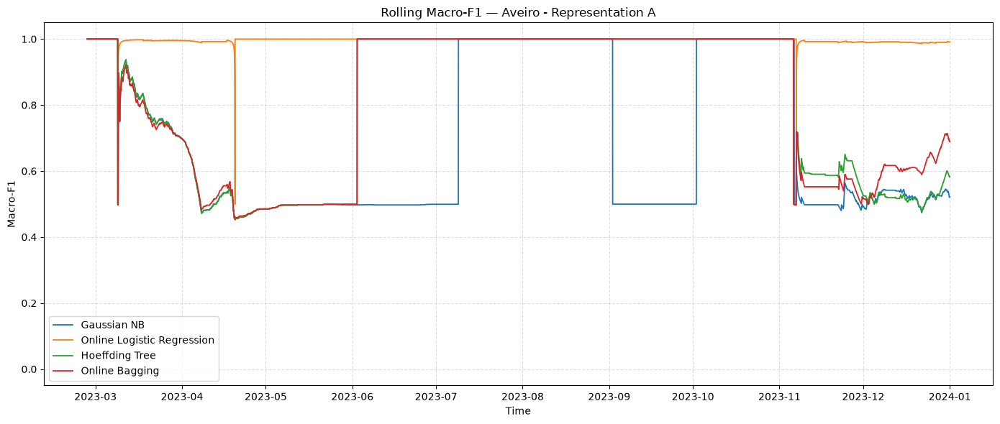

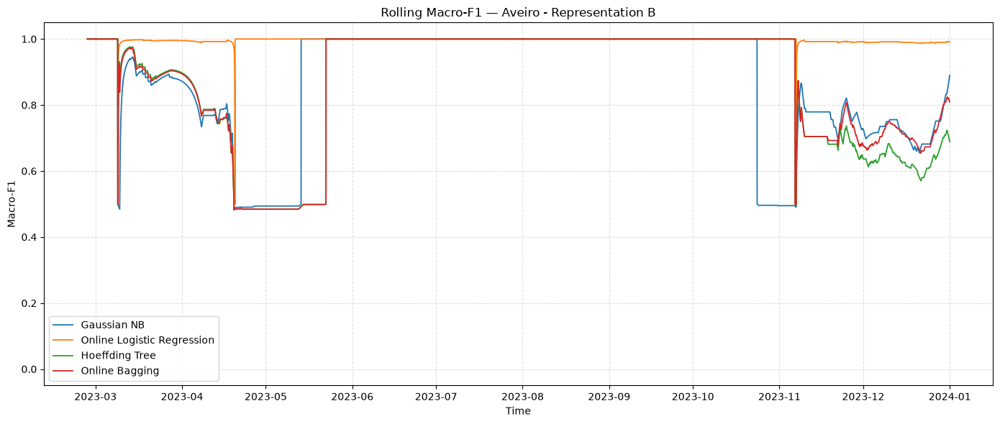

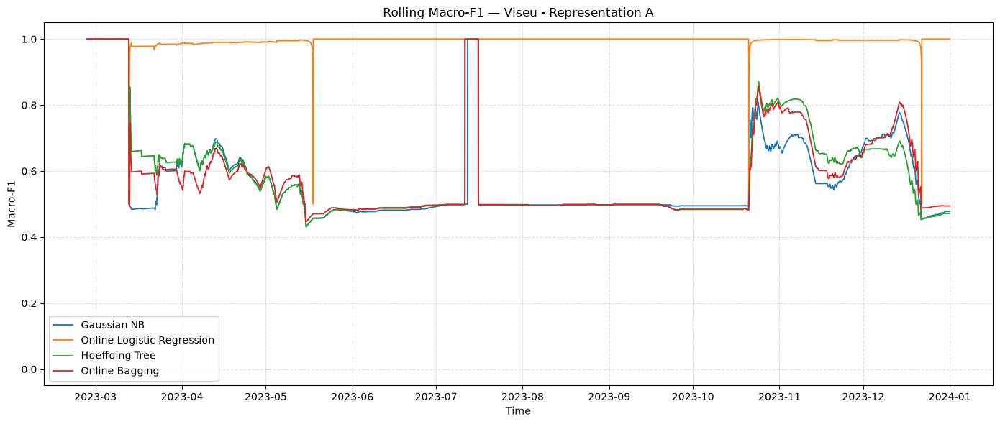

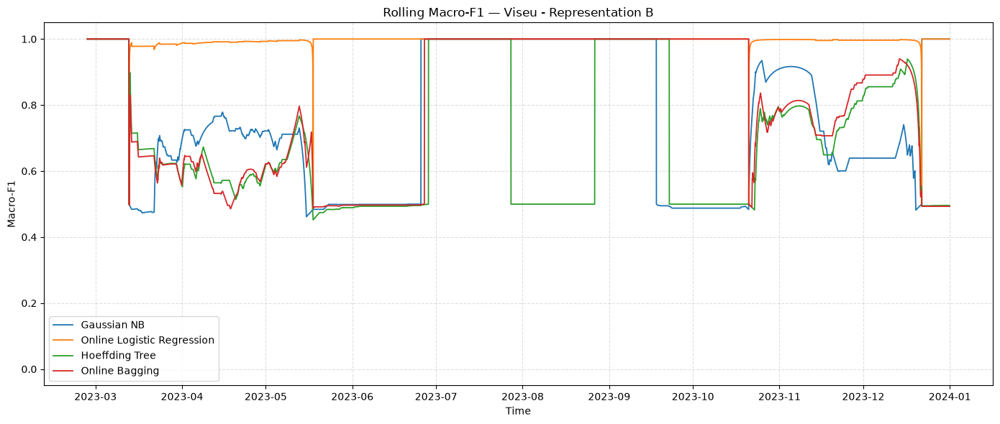

In [ ]:
def plot_online_performance(
    history: pd.DataFrame,
    title: str,
):
    fig, ax = plt.subplots(figsize=(14, 6))

    metric_columns = [
        column
        for column in history.columns
        if column.endswith("rolling_macro_f1")
    ]

    for column in metric_columns:
        ax.plot(
            history["time"],
            history[column],
            label=column.replace(" | rolling_macro_f1", ""),
            linewidth=1.3,
        )

    ax.set_title(f"Rolling Macro-F1 — {title}")
    ax.set_xlabel("Time")
    ax.set_ylabel("Macro-F1")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend()
    fig.tight_layout()
    plt.show()

for name, history in experiments.items():
    plot_online_performance(history, name)

### Compare the features representations

representation                         A      B
city   model                                   
Aveiro Gaussian NB                 0.770  0.915
       Hoeffding Tree              0.798  0.884
       Online Bagging              0.835  0.904
       Online Logistic Regression  0.997  0.997
Viseu  Gaussian NB                 0.851  0.916
       Hoeffding Tree              0.863  0.900
       Online Bagging              0.873  0.908
       Online Logistic Regression  0.998  0.998

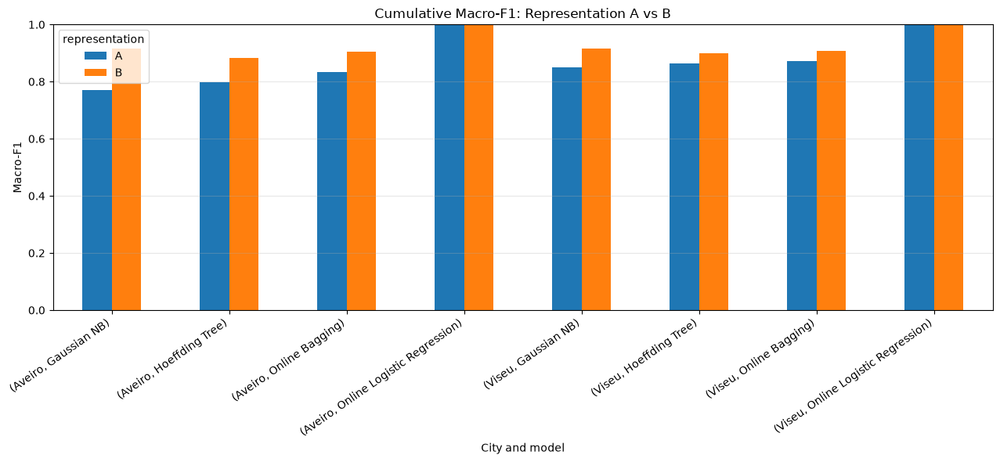

In [ ]:
macro_f1_comparison = comparison.pivot_table(
    index=["city", "model"],
    columns="representation",
    values="macro_f1",
)

display(macro_f1_comparison.round(3))

ax = macro_f1_comparison.plot(
    kind="bar",
    figsize=(13, 6),
)

ax.set_title("Cumulative Macro-F1: Representation A vs B")
ax.set_xlabel("City and model")
ax.set_ylabel("Macro-F1")
ax.set_ylim(0, 1)
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Track incremental mean temperature

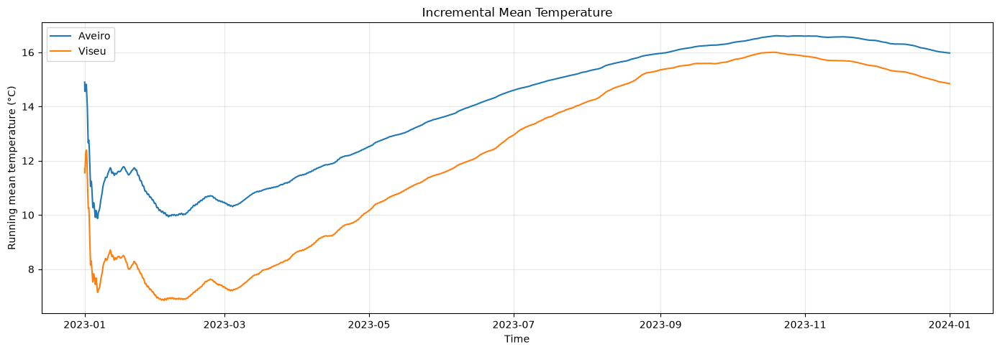

In [ ]:
def track_incremental_mean(
    df: pd.DataFrame,
) -> pd.DataFrame:
    running_mean = stats.Mean()
    records = []

    for row in df.sort_values("time").itertuples(index=False):
        running_mean.update(float(row.temperature))

        records.append({
            "time": row.time,
            "temperature": row.temperature,
            "running_mean": running_mean.get(),
        })

    return pd.DataFrame(records)


mean_results = {
    city: track_incremental_mean(df)
    for city, df in clean_data.items()
}

fig, ax = plt.subplots(figsize=(14, 5))

for city, result in mean_results.items():
    ax.plot(
        result["time"],
        result["running_mean"],
        label=city,
    )

ax.set_title("Incremental Mean Temperature")
ax.set_xlabel("Time")
ax.set_ylabel("Running mean temperature (°C)")
ax.legend()
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

In [ ]:
# ---- CELL T0: tunable models (REPLACES the old "make_models" cell) ----
import json
from joblib import Parallel, delayed
from sklearn.model_selection import ParameterGrid, ParameterSampler

# ---- tuning protocol (document every value in the report) ----
TUNING_METRIC = "macro_f1"          # prequential score used to choose a configuration
TUNE_SCOPE = "pooled"               # "pooled": one configuration for both cities (fair city comparison); "per_city"
TUNE_INNER_WARMUP = 0.30            # inside the tuning data: first 30 % only trained on, the rest scored
TUNE_FRACTION = 0.25                # only used when warm-up features are NOT exported (see T1)
TUNING_MIN_GAIN = 0.002             # a candidate must beat the default by this much, otherwise keep the default
TUNING_N_JOBS = 1                   # 1 = sequential; -1 = all cores (tuning only, never used for timing)
TUNE_N_ITER = {                     # candidates evaluated per model (default is always included)
    "Online Logistic Regression": 15,
    "Hoeffding Tree": 30,
    "Online Bagging": 20,
    "Adaptive Random Forest": 20,
}
warmup_stream_data = None           # dict city -> DataFrame (past-only features + target_hot for the warm-up rows)
                                    # set it once the warm-up features are exported; otherwise T1 uses a fallback


def build_gaussian_nb():
    return naive_bayes.GaussianNB()


def build_logistic(lr=0.05, l2=0.0):
    return compose.Pipeline(
        preprocessing.StandardScaler(),                 # online scaler: learns from the past only
        linear_model.LogisticRegression(optimizer=optim.SGD(lr), l2=l2),
    )


def build_hoeffding_tree(grace_period=50, delta=1e-3, tau=0.10, leaf_prediction="mc"):
    return tree.HoeffdingTreeClassifier(grace_period=grace_period, delta=delta, tau=tau,
                                        leaf_prediction=leaf_prediction)


def build_bagging(n_models=10, grace_period=50, delta=1e-3, tau=0.10, leaf_prediction="mc", seed=RANDOM_SEED):
    return ensemble.BaggingClassifier(
        model=build_hoeffding_tree(grace_period, delta, tau, leaf_prediction), n_models=n_models, seed=seed)


def build_arf(n_models=10, lambda_value=6, max_features="sqrt", grace_period=50, delta=1e-3, tau=0.10,
              leaf_prediction="mc", seed=RANDOM_SEED):
    return forest.ARFClassifier(n_models=n_models, lambda_value=lambda_value, max_features=max_features,
                                grace_period=grace_period, delta=delta, tau=tau,
                                leaf_prediction=leaf_prediction, seed=seed)


MODEL_SPECS = {
    "Gaussian NB": dict(build=build_gaussian_nb, default={}, space={}),      # River's GaussianNB has no hyperparameters
    "Online Logistic Regression": dict(
        build=build_logistic, default=dict(lr=0.05, l2=0.0),
        space=dict(lr=[0.001, 0.005, 0.01, 0.05, 0.1, 0.5], l2=[0.0, 1e-4, 1e-3, 1e-2])),
    "Hoeffding Tree": dict(
        build=build_hoeffding_tree, default=dict(grace_period=50, delta=1e-3, tau=0.10, leaf_prediction="mc"),
        space=dict(grace_period=[25, 50, 100, 200], delta=[1e-7, 1e-5, 1e-3, 1e-2],
                   tau=[0.02, 0.05, 0.10, 0.20], leaf_prediction=["mc", "nb", "nba"])),
    "Online Bagging": dict(
        build=build_bagging, default=dict(n_models=10, grace_period=50, delta=1e-3, tau=0.10, leaf_prediction="mc"),
        space=dict(n_models=[5, 10, 20], grace_period=[25, 50, 100], delta=[1e-5, 1e-3], tau=[0.05, 0.10, 0.20])),
    "Adaptive Random Forest": dict(
        build=build_arf,
        default=dict(n_models=10, lambda_value=6, max_features="sqrt", grace_period=50, delta=1e-3, tau=0.10,
                     leaf_prediction="mc"),
        space=dict(n_models=[5, 10, 20], lambda_value=[3, 6, 10], max_features=["sqrt", "log2"],
                   grace_period=[25, 50, 100], delta=[1e-5, 1e-3], tau=[0.05, 0.10, 0.20])),
}
MANDATORY_MODELS = list(MODEL_SPECS)


def make_models(params_by_model=None, include_baselines=True, include_optional=False, seed=RANDOM_SEED):
    """Fresh instances every call. params_by_model=None -> default hyperparameters for every model."""
    params_by_model = params_by_model or {}
    models = {name: spec["build"](**{**spec["default"], **params_by_model.get(name, {})})
              for name, spec in MODEL_SPECS.items()}
    if include_baselines:
        models = {"Majority class (baseline)": dummy.PriorClassifier(),
                  "No-change (baseline)": dummy.NoChangeClassifier(), **models}
    if include_optional:                         # extensions: not tuned, they do not replace the five mandatory models
        models["Leveraging Bagging"] = ensemble.LeveragingBaggingClassifier(
            model=build_hoeffding_tree(), n_models=10, w=6, seed=seed)
        models["Streaming Random Patches"] = ensemble.SRPClassifier(
            model=build_hoeffding_tree(), n_models=10, subspace_size=0.6, training_method="patches", lam=6, seed=seed)
    return models




In [ ]:
# ---- CELL T1: where tuning is allowed to look (never at the scored evaluation stream) ----
def build_splits() -> dict:
    """For each city: `warmup` = data used for tuning AND for the final unscored warm-up; `evaluation` = scored stream."""
    splits = {}
    if warmup_stream_data is not None:
        for city in CITIES:
            splits[city] = dict(warmup=warmup_stream_data[city].sort_values("time").reset_index(drop=True),
                                evaluation=stream_data[city], source="warm-up period")
    else:
        # Fallback: the evaluation stream has no warm-up rows, so its FIRST part plays the warm-up role.
        # Every model (default and tuned) is then scored only on the remaining, never-tuned part.
        reference = stream_data[CITIES[0]]
        cut_time = reference["time"].iloc[int(len(reference) * TUNE_FRACTION)]
        for city in CITIES:
            df = stream_data[city]
            splits[city] = dict(warmup=df[df["time"] < cut_time].reset_index(drop=True),
                                evaluation=df[df["time"] >= cut_time].reset_index(drop=True),
                                source=f"first {TUNE_FRACTION:.0%} of the evaluation stream")
    for city, sp in splits.items():
        assert sp["warmup"]["time"].max() < sp["evaluation"]["time"].min(), f"{city}: tuning data overlaps scored data"
        assert sp["warmup"][TARGET_COL].nunique() == 2, f"{city}: tuning data contains only one class"
    return splits


splits = build_splits()
print(f"Tuning data = {splits[CITIES[0]]['source']}")
for city, sp in splits.items():
    print(f"  {city}: tune/warm-up {len(sp['warmup']):,} rows "
          f"({sp['warmup'][TARGET_COL].mean():.1%} events) | scored {len(sp['evaluation']):,} rows "
          f"({sp['evaluation'][TARGET_COL].mean():.1%} events)")




In [ ]:
# ---- CELL T2: hyperparameter search (prequential, tuning data only) ----
def score_config(name: str, params: dict, df: pd.DataFrame, feature_cols: list[str]) -> dict:
    """Prequential score of ONE configuration: learn on the first part unscored, then predict -> evaluate -> learn."""
    model = MODEL_SPECS[name]["build"](**params)
    n_train_only = int(len(df) * TUNE_INNER_WARMUP)
    evaluator = StreamingBinaryEvaluator(WINDOW_SIZE)
    for i, (_, x, y) in enumerate(iter_events(df, feature_cols)):
        if i < n_train_only:
            model.learn_one(x, y)
            continue
        y_pred = model.predict_one(x)
        evaluator.update(y, None if y_pred is None else int(y_pred))
        model.learn_one(x, y)
    snap = evaluator.snapshot()
    return {k: snap[k] for k in ("macro_f1", "f1", "precision", "recall", "accuracy")}


def candidate_configs(name: str, n_iter: int, seed: int = RANDOM_SEED) -> list[dict]:
    spec = MODEL_SPECS[name]
    grid = ParameterGrid(spec["space"])
    sampled = list(grid) if len(grid) <= n_iter else list(ParameterSampler(spec["space"], n_iter, random_state=seed))
    candidates = [dict(spec["default"])]                          # the default is always a candidate
    candidates += [{**spec["default"], **p} for p in sampled if {**spec["default"], **p} != spec["default"]]
    return candidates


def tune_one(name, representation, group_cities, n_iter):
    feature_cols = REPRESENTATIONS[representation]
    candidates = candidate_configs(name, n_iter)
    jobs = [(i, city) for i in range(len(candidates)) for city in group_cities]
    scored = Parallel(n_jobs=TUNING_N_JOBS)(
        delayed(score_config)(name, candidates[i], splits[city]["warmup"], feature_cols) for i, city in jobs)
    rows = {}
    for (i, city), s in zip(jobs, scored):
        rows.setdefault(i, {"candidate": i, "params": candidates[i]})[city] = s
    out = []
    for i, entry in rows.items():
        per_city = {c: entry[c][TUNING_METRIC] for c in group_cities}
        out.append({"candidate": i, "params": entry["params"], "is_default": i == 0,
                    "tune_score": float(np.mean(list(per_city.values()))),
                    **{f"tune_{TUNING_METRIC}_{c}": v for c, v in per_city.items()},
                    "tune_event_f1": float(np.mean([entry[c]["f1"] for c in group_cities]))})
    table = pd.DataFrame(out)
    default_score = table.loc[table["is_default"], "tune_score"].iloc[0]
    best = table.loc[table["tune_score"].idxmax()]
    chosen = best if best["tune_score"] - default_score >= TUNING_MIN_GAIN else table.loc[table["is_default"]].iloc[0]
    table["selected"] = table["candidate"] == chosen["candidate"]
    return table, chosen["params"]


groups = {"all": CITIES} if TUNE_SCOPE == "pooled" else {city: [city] for city in CITIES}
tuning_tables, best_params = [], {}
t_start = time.perf_counter()

for group, group_cities in groups.items():
    for representation in REPRESENTATIONS:
        best_params[(group, representation)] = {}
        for name, spec in MODEL_SPECS.items():
            if not spec["space"]:
                best_params[(group, representation)][name] = {}
                print(f"[{group} | {representation}] {name}: no hyperparameters to tune")
                continue
            table, chosen = tune_one(name, representation, group_cities, TUNE_N_ITER[name])
            best_params[(group, representation)][name] = chosen
            tuning_tables.append(table.assign(scope_group=group, representation=representation, model=name))
            print(f"[{group} | {representation}] {name}: {len(table)} configs, best tune {TUNING_METRIC} = "
                  f"{table['tune_score'].max():.3f} (default {table.loc[table['is_default'], 'tune_score'].iloc[0]:.3f}) "
                  f"-> {chosen}   [{time.perf_counter() - t_start:,.0f} s]")

tuning_results = pd.concat(tuning_tables, ignore_index=True)
tuning_results["params"] = tuning_results["params"].map(lambda p: json.dumps(p, sort_keys=True))
tuning_results.to_csv(RESULTS_DIR / "tuning_results.csv", index=False)

best_table = pd.DataFrame(
    [{"scope_group": g, "representation": r, "model": m, "best_params": json.dumps(p, sort_keys=True)}
     for (g, r), models_ in best_params.items() for m, p in models_.items()])
best_table.to_csv(RESULTS_DIR / "best_hyperparameters.csv", index=False)
display(best_table)


def params_for(city: str, representation: str) -> dict:
    return best_params[("all" if TUNE_SCOPE == "pooled" else city, representation)]




In [ ]:
# ---- CELL T3: final evaluation: default vs tuned on the SAME scored stream ----
def run_final_evaluation(tuned: bool):
    experiments_, results_ = {}, []
    for city in CITIES:
        sp = splits[city]
        for representation, feature_cols in REPRESENTATIONS.items():
            chosen = params_for(city, representation) if tuned else {}
            models = make_models(chosen)
            print(f"Running {'TUNED  ' if tuned else 'DEFAULT'}: {city} - Representation {representation} "
                  f"({len(sp['warmup']):,} warm-up + {len(sp['evaluation']):,} scored events)")
            history, scores = track_online_performance(sp["evaluation"], feature_cols,
                                                       df_warmup=sp["warmup"], models=models)
            scores["params"] = scores["model"].map(lambda m: json.dumps(chosen.get(m, {}), sort_keys=True))
            scores.insert(0, "representation", representation)
            scores.insert(0, "city", city)
            scores["config"] = "tuned" if tuned else "default"
            experiments_[experiment_key(city, representation)] = history
            results_.append(scores)
    return experiments_, pd.concat(results_, ignore_index=True)


experiments_default, comparison_default = run_final_evaluation(tuned=False)
experiments_tuned, comparison_tuned = run_final_evaluation(tuned=True)

# Downstream cells (curves, confusion matrices, P1-P7) read `comparison` and `experiments`: point them at the tuned run.
comparison, experiments = comparison_tuned.copy(), experiments_tuned

effect_metrics = ["macro_f1", "f1", "precision", "recall", "accuracy", "pred_ms_per_event", "update_ms_per_event"]
keys = ["city", "representation", "model"]
tuning_effect = (comparison_default[keys + effect_metrics]
                 .merge(comparison_tuned[keys + effect_metrics + ["params"]], on=keys, suffixes=("_default", "_tuned")))
for metric in effect_metrics:
    tuning_effect[f"delta_{metric}"] = tuning_effect[f"{metric}_tuned"] - tuning_effect[f"{metric}_default"]
tuning_effect = tuning_effect[tuning_effect["model"].isin(MANDATORY_MODELS)]
display(tuning_effect[keys + ["macro_f1_default", "macro_f1_tuned", "delta_macro_f1", "delta_precision", "delta_recall",
                              "delta_update_ms_per_event", "params"]].round(3))

# ---- exports ----
comparison_default.to_csv(RESULTS_DIR / "metrics_default.csv", index=False)
comparison_tuned.to_csv(RESULTS_DIR / "metrics_tuned.csv", index=False)
tuning_effect.to_csv(RESULTS_DIR / "tuning_effect.csv", index=False)

configuration = {
    "python": platform.python_version(),
    **{f"version_{p}": importlib_metadata.version(p) for p in ("river", "numpy", "pandas", "scikit-learn")},
    "random_seed": RANDOM_SEED, "target": TARGET_COL,
    "tau_t_hot": meta.get("tau_t_hot"), "hot_percentile": meta.get("hot_percentile"),
    "warmup_start": meta.get("warmup_start"), "warmup_end": meta.get("warmup_end"),
    "tuning_data": splits[CITIES[0]]["source"],
    "tune_fraction_if_fallback": TUNE_FRACTION, "tune_inner_warmup": TUNE_INNER_WARMUP,
    "tune_scope": TUNE_SCOPE, "tuning_metric": TUNING_METRIC, "tuning_min_gain": TUNING_MIN_GAIN,
    "tune_n_iter": TUNE_N_ITER, "search_spaces": {m: s["space"] for m, s in MODEL_SPECS.items()},
    "default_params": {m: s["default"] for m, s in MODEL_SPECS.items()},
    "selected_params": {f"{g}|{r}": p for (g, r), p in best_params.items()},
    "scored_events_per_city": {c: len(sp["evaluation"]) for c, sp in splits.items()},
    "evaluation_start": str(min(sp["evaluation"]["time"].min() for sp in splits.values())),
    "evaluation_end": str(max(sp["evaluation"]["time"].max() for sp in splits.values())),
    "rolling_window_size": WINDOW_SIZE, "history_stride": HISTORY_STRIDE,
    "features_A": REPRESENTATIONS["A"], "features_B": REPRESENTATIONS["B"],
}
pd.DataFrame({"parameter": list(configuration), "value": [str(v) for v in configuration.values()]}).to_csv(
    RESULTS_DIR / "configurations.csv", index=False)
print("Saved: metrics_default.csv, metrics_tuned.csv, tuning_effect.csv, tuning_results.csv, "
      "best_hyperparameters.csv, configurations.csv")



In [ ]:

# ---- CELL T4: plots (needs CELL P0 for the colours and helpers) ----
def plot_tuning_landscape(filename="tuning_landscape"):
    """How much do hyperparameters matter? Every candidate's tuning score, with default and selected marked."""
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=1, cols=len(reps), shared_yaxes=True,
                        subplot_titles=[f"Representation {r}" for r in reps], horizontal_spacing=0.05)
    legend_seen = set()
    for cj, rep in enumerate(reps, start=1):
        for name in MANDATORY_MODELS:
            sub = tuning_results[(tuning_results["representation"] == rep) & (tuning_results["model"] == name)]
            if sub.empty:
                continue
            color = MODEL_COLORS.get(name)
            fig.add_trace(go.Box(y=sub["tune_score"], x=[name] * len(sub), name=name, marker_color=color,
                                 boxpoints="all", jitter=0.4, pointpos=0, showlegend=False,
                                 customdata=sub["params"], hovertemplate="%{y:.3f}<br>%{customdata}<extra></extra>"),
                          row=1, col=cj)
            for flag, symbol, label in ((sub["is_default"], "circle-open", "Default"), (sub["selected"], "star", "Selected")):
                pick = sub[flag]
                fig.add_trace(go.Scatter(x=[name] * len(pick), y=pick["tune_score"], mode="markers", name=label,
                                         legendgroup=label, showlegend=label not in legend_seen,
                                         marker=dict(symbol=symbol, size=14, color="black", line=dict(width=2)),
                                         hovertemplate=label + ": %{y:.3f}<extra></extra>"), row=1, col=cj)
                legend_seen.add(label)
    fig.update_yaxes(title_text=f"Tuning {TUNING_METRIC.replace('_', '-')} (prequential)", col=1)
    fig.update_xaxes(tickangle=-25)
    fig.update_layout(title="Hyperparameter sensitivity on the tuning data (each dot = one configuration)",
                      height=520, legend=dict(orientation="h", y=1.12, x=0))
    show_and_save(fig, filename)


def plot_tuning_effect(filename="tuning_effect"):
    """Gain on the SCORED stream: tuned minus default, same history, same warm-up."""
    metric_colors = {"macro_f1": "#08519c", "precision": "#fd8d3c", "recall": "#31a354"}
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(CITIES), cols=len(reps), shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for c in CITIES for r in reps],
                        vertical_spacing=0.14, horizontal_spacing=0.05)
    for ri, city in enumerate(CITIES, start=1):
        for cj, rep in enumerate(reps, start=1):
            sub = tuning_effect[(tuning_effect["city"] == city) & (tuning_effect["representation"] == rep)]
            sub = sub.set_index("model").reindex(MANDATORY_MODELS).dropna(subset=["macro_f1_default"])
            for metric, color in metric_colors.items():
                fig.add_trace(go.Bar(
                    y=sub.index, x=sub[f"delta_{metric}"], orientation="h", name=metric.replace("_", "-"),
                    marker_color=color, legendgroup=metric, showlegend=(ri == 1 and cj == 1),
                    customdata=np.c_[sub["delta_update_ms_per_event"], sub["params"]],
                    hovertemplate="%{y}<br>Δ = %{x:+.3f}<br>Δ update time = %{customdata[0]:+.3f} ms/event"
                                  "<br>%{customdata[1]}<extra>" + metric + "</extra>"), row=ri, col=cj)
            fig.add_vline(x=0, line=dict(color="black", width=1), row=ri, col=cj)
    fig.update_yaxes(autorange="reversed")
    fig.update_xaxes(title_text="Δ (tuned − default)", zeroline=False, row=len(CITIES))
    fig.update_layout(title="Effect of hyperparameter tuning on the scored stream", barmode="group",
                      height=300 * len(CITIES) + 140, legend=dict(orientation="h", y=1.1, x=0))
    show_and_save(fig, filename)


plot_tuning_landscape()
plot_tuning_effect()

In [ ]:
# ---- CELL F0: tuned logistic regression helpers (needs Cell A, P0 and T0-T3) ----
LR_NAME = "Online Logistic Regression"


def build_tuned_logistic(city: str, representation: str):
    """Fresh Pipeline(StandardScaler -> LogisticRegression) with the hyperparameters selected in T2."""
    params = {**MODEL_SPECS[LR_NAME]["default"], **params_for(city, representation)[LR_NAME]}
    return MODEL_SPECS[LR_NAME]["build"](**params)


def lr_coefficients(model) -> tuple[dict, float]:
    """Weights live in STANDARDISED feature space (online StandardScaler), so they are comparable across features."""
    estimator = list(model.steps.values())[-1]
    return dict(estimator.weights), float(estimator.intercept)


def logistic_weight_history(city: str, representation: str, stride: int = HISTORY_STRIDE) -> pd.DataFrame:
    """Coefficients over the stream: learn on the warm-up, then keep learning on the scored stream (one pass,
    chronological). No scoring happens here, so there is no predict/evaluate step to order."""
    split, cols = splits[city], REPRESENTATIONS[representation]
    model = build_tuned_logistic(city, representation)
    for _, x, y in iter_events(split["warmup"], cols):
        model.learn_one(x, y)
    rows, n_events = [], len(split["evaluation"])
    for i, (time_, x, y) in enumerate(iter_events(split["evaluation"], cols), start=1):
        model.learn_one(x, y)
        if i % stride == 0 or i == n_events:
            weights, bias = lr_coefficients(model)
            rows.append({"time": time_, "bias": bias, **{f"w:{c}": weights.get(c, 0.0) for c in cols}})
    return pd.DataFrame(rows)


def score_logistic(city: str, representation: str, feature_cols: list[str]) -> dict:
    """Prequential score (warm-up -> predict -> evaluate -> learn) of the tuned logistic regression
    on a chosen subset of the features. Same history and warm-up as every other model."""
    split = splits[city]
    params = {**MODEL_SPECS[LR_NAME]["default"], **params_for(city, representation)[LR_NAME]}
    model = MODEL_SPECS[LR_NAME]["build"](**params)
    last_label = None
    for _, x, y in iter_events(split["warmup"], feature_cols):
        model.learn_one(x, y)
        last_label = y
    evaluator = StreamingBinaryEvaluator(WINDOW_SIZE, last_label)
    for _, x, y in iter_events(split["evaluation"], feature_cols):
        y_pred = model.predict_one(x)
        evaluator.update(y, None if y_pred is None else int(y_pred))
        model.learn_one(x, y)
    return evaluator.snapshot()




In [ ]:
# ---- CELL F1: coefficients, ablations and the summary table ----
weight_histories = {(c, r): logistic_weight_history(c, r) for c in CITIES for r in REPRESENTATIONS}

relevance_rows = []
for city in CITIES:
    for representation, cols in REPRESENTATIONS.items():
        full = score_logistic(city, representation, cols)
        final_weights = weight_histories[(city, representation)].iloc[-1]
        corr = pd.concat([splits[city]["warmup"], splits[city]["evaluation"]])[cols + [TARGET_COL]].corr()[TARGET_COL]
        for feature in cols:
            without = score_logistic(city, representation, [c for c in cols if c != feature])
            alone = score_logistic(city, representation, [feature])
            relevance_rows.append({
                "city": city, "representation": representation, "feature": feature,
                "coef_standardised": final_weights[f"w:{feature}"],
                "abs_coef": abs(final_weights[f"w:{feature}"]),
                "corr_with_target": corr[feature],
                "macro_f1_full_model": full["macro_f1"],
                "macro_f1_without_feature": without["macro_f1"],
                "drop_in_macro_f1": full["macro_f1"] - without["macro_f1"],     # > 0: removing it hurts
                "drop_in_event_f1": full["f1"] - without["f1"],
                "macro_f1_feature_alone": alone["macro_f1"],
                "event_f1_feature_alone": alone["f1"],
            })

feature_relevance = pd.DataFrame(relevance_rows)
feature_relevance["rank_by_abs_coef"] = feature_relevance.groupby(["city", "representation"])["abs_coef"].rank(
    ascending=False, method="min").astype(int)
feature_relevance["rank_by_drop"] = feature_relevance.groupby(["city", "representation"])["drop_in_macro_f1"].rank(
    ascending=False, method="min").astype(int)
feature_relevance.to_csv(RESULTS_DIR / "feature_relevance_logistic.csv", index=False)
display(feature_relevance.sort_values(["city", "representation", "rank_by_abs_coef"]).round(3))



In [ ]:
# ---- CELL F2: plots ----
def plot_logistic_coefficients(filename="logistic_coefficients"):
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(CITIES), cols=len(reps), subplot_titles=[f"{c} – Representation {r}" for c in CITIES for r in reps],
                        vertical_spacing=0.16, horizontal_spacing=0.2)
    for ri, city in enumerate(CITIES, start=1):
        for cj, rep in enumerate(reps, start=1):
            sub = feature_relevance[(feature_relevance["city"] == city) & (feature_relevance["representation"] == rep)]
            sub = sub.sort_values("abs_coef")
            fig.add_trace(go.Bar(
                y=sub["feature"], x=sub["coef_standardised"], orientation="h",
                marker_color=np.where(sub["coef_standardised"] >= 0, "#d62728", "#1f77b4"), showlegend=False,
                customdata=np.c_[sub["corr_with_target"], sub["drop_in_macro_f1"]],
                hovertemplate="%{y}<br>coef = %{x:+.3f}<br>corr with target = %{customdata[0]:+.2f}"
                              "<br>macro-F1 drop if removed = %{customdata[1]:+.3f}<extra></extra>"), row=ri, col=cj)
            fig.add_vline(x=0, line=dict(color="black", width=1), row=ri, col=cj)
            fig.update_xaxes(title_text="Coefficient (per 1 std of the feature)", row=ri, col=cj)
    fig.update_layout(title="Tuned online logistic regression: standardised coefficients at the end of the stream "
                            "(red = raises the event odds, blue = lowers them)",
                      height=330 * len(CITIES) + 130, margin=dict(l=160))
    show_and_save(fig, filename)


def plot_logistic_weight_paths(filename="logistic_weight_paths"):
    reps = list(REPRESENTATIONS)
    palette = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf"]
    fig = make_subplots(rows=len(CITIES), cols=len(reps), shared_xaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for c in CITIES for r in reps],
                        vertical_spacing=0.1, horizontal_spacing=0.05)
    legend_seen = set()
    for ri, city in enumerate(CITIES, start=1):
        for cj, rep in enumerate(reps, start=1):
            history = weight_histories[(city, rep)]
            for k, feature in enumerate(REPRESENTATIONS[rep]):
                fig.add_trace(go.Scatter(x=history["time"], y=history[f"w:{feature}"], mode="lines", name=feature,
                                         legendgroup=feature, showlegend=feature not in legend_seen,
                                         line=dict(color=palette[k % len(palette)], width=1.8),
                                         hovertemplate="%{y:+.3f}"), row=ri, col=cj)
                legend_seen.add(feature)
            fig.add_hline(y=0, line=dict(color="black", width=1, dash="dot"), row=ri, col=cj)
        fig.update_yaxes(title_text="Coefficient", row=ri, col=1)
    fig.update_layout(title="How the logistic-regression coefficients evolve while the stream is processed",
                      height=330 * len(CITIES) + 150, hovermode="x unified", legend=dict(orientation="h", y=-0.1, x=0))
    show_and_save(fig, filename)


def plot_feature_ablation(column, title, x_title, filename, reference=None):
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(CITIES), cols=len(reps), subplot_titles=[f"{c} – Representation {r}" for c in CITIES for r in reps],
                        vertical_spacing=0.16, horizontal_spacing=0.2)
    for ri, city in enumerate(CITIES, start=1):
        for cj, rep in enumerate(reps, start=1):
            sub = feature_relevance[(feature_relevance["city"] == city) & (feature_relevance["representation"] == rep)]
            sub = sub.sort_values(column)
            fig.add_trace(go.Bar(y=sub["feature"], x=sub[column], orientation="h", marker_color="#08519c",
                                 showlegend=False, hovertemplate="%{y}<br>%{x:.3f}<extra></extra>"), row=ri, col=cj)
            if reference:
                fig.add_vline(x=sub[reference].iloc[0], line=dict(color="#d62728", dash="dash", width=1.5), row=ri, col=cj,
                              annotation_text="all features", annotation_position="top")
            fig.update_xaxes(title_text=x_title, row=ri, col=cj)
    fig.update_layout(title=title, height=330 * len(CITIES) + 130, margin=dict(l=160))
    show_and_save(fig, filename)


plot_logistic_coefficients()
plot_logistic_weight_paths()
plot_feature_ablation("drop_in_macro_f1", "Leave-one-feature-out: macro-F1 lost when a feature is removed (>0: it was helping)",
                      "Δ macro-F1 (full model − model without the feature)", "feature_drop_one")
plot_feature_ablation("macro_f1_feature_alone", "Single-feature models: macro-F1 using only that feature",
                      "Macro-F1 (feature alone)", "feature_alone", reference="macro_f1_full_model")

In [ ]:
# ---- CELL M1: confusion matrices of the TUNED models (needs CELL P0 for helpers and colours) ----
def plot_confusion_matrices_tuned(results: pd.DataFrame, city: str, representation: str, filename: str | None = None) -> None:
    """One row of heat-maps per city x representation. Colour and % = share of the TRUE class (row-normalised);
    the count is in brackets. Top-right = false alarms, bottom-left = missed events."""
    sub = results[(results["city"] == city) & (results["representation"] == representation)]
    fig = make_subplots(rows=1, cols=len(sub), subplot_titles=[m.replace(" (baseline)", "<br>(baseline)").replace(
        "Online Logistic Regression", "Online Logistic<br>Regression").replace("Adaptive Random Forest",
        "Adaptive Random<br>Forest") for m in sub["model"]], horizontal_spacing=0.03)
    labels = ["no event", "event"]
    for col, r in enumerate(sub.itertuples(index=False), start=1):
        counts = np.array([[r.tn, r.fp], [r.fn, r.tp]])
        shares = counts / counts.sum(axis=1, keepdims=True).clip(min=1)
        text = [[f"{shares[a, b]:.0%}<br>({counts[a, b]:,})" for b in range(2)] for a in range(2)]
        fig.add_trace(go.Heatmap(
            z=shares, x=labels, y=labels, text=text, texttemplate="%{text}", colorscale="Blues", zmin=0, zmax=1,
            showscale=False, customdata=counts,
            hovertemplate="true: %{y}<br>predicted: %{x}<br>share of true class: %{z:.1%}<br>count: %{customdata:,}"
                          f"<extra>{r.model}</extra>"), row=1, col=col)
        fig.update_yaxes(autorange="reversed", showticklabels=(col == 1), row=1, col=col)
        fig.update_xaxes(title_text="Predicted", row=1, col=col)
    fig.update_yaxes(title_text="True", row=1, col=1)
    fig.update_annotations(font_size=11)
    fig.update_layout(title=f"Confusion matrices, tuned models – {city}, Representation {representation}",
                      height=420, width=max(900, 190 * len(sub)), margin=dict(t=110))
    show_and_save(fig, filename or f"confusion_tuned_{city.lower()}_{representation}")


for city in CITIES:
    for representation in REPRESENTATIONS:
        plot_confusion_matrices_tuned(comparison_tuned, city, representation)

# rates behind the heat-maps, saved for the report
confusion_tuned = comparison_tuned[["city", "representation", "model", "params", "tn", "fp", "fn", "tp"]].copy()
confusion_tuned["recall_tpr"] = confusion_tuned["tp"] / (confusion_tuned["tp"] + confusion_tuned["fn"])
confusion_tuned["miss_rate_fnr"] = 1 - confusion_tuned["recall_tpr"]
confusion_tuned["false_alarm_rate_fpr"] = confusion_tuned["fp"] / (confusion_tuned["fp"] + confusion_tuned["tn"])
confusion_tuned["specificity_tnr"] = 1 - confusion_tuned["false_alarm_rate_fpr"]
confusion_tuned.to_csv(RESULTS_DIR / "confusion_matrices_tuned.csv", index=False)
display(confusion_tuned.drop(columns="params").round(3))



In [ ]:
# ---- CELL M2: what tuning changed in the errors (tuned minus default) ----
def plot_error_shift(filename="confusion_error_shift"):
    """Change in missed events (FN) and false alarms (FP). Below zero = fewer errors after tuning."""
    keys = ["city", "representation", "model"]
    shift = comparison_default[keys + ["fn", "fp"]].merge(comparison_tuned[keys + ["fn", "fp"]], on=keys,
                                                          suffixes=("_default", "_tuned"))
    shift = shift[shift["model"].isin(MANDATORY_MODELS)]
    shift["d_fn"] = shift["fn_tuned"] - shift["fn_default"]
    shift["d_fp"] = shift["fp_tuned"] - shift["fp_default"]
    reps = list(REPRESENTATIONS)
    fig = make_subplots(rows=len(CITIES), cols=len(reps), shared_xaxes=True, shared_yaxes=True,
                        subplot_titles=[f"{c} – Representation {r}" for c in CITIES for r in reps],
                        vertical_spacing=0.14, horizontal_spacing=0.05)
    for ri, city in enumerate(CITIES, start=1):
        for cj, rep in enumerate(reps, start=1):
            part = shift[(shift["city"] == city) & (shift["representation"] == rep)].set_index("model")
            part = part.reindex(MANDATORY_MODELS).dropna(subset=["d_fn"])
            for column, label, color in (("d_fn", "Missed events (FN)", "#d62728"), ("d_fp", "False alarms (FP)", "#ff7f0e")):
                fig.add_trace(go.Bar(
                    y=part.index, x=part[column], orientation="h", name=label, marker_color=color, legendgroup=label,
                    showlegend=(ri == 1 and cj == 1),
                    hovertemplate="%{y}<br>Δ = %{x:+,.0f} hours<extra>" + label + "</extra>"), row=ri, col=cj)
            fig.add_vline(x=0, line=dict(color="black", width=1), row=ri, col=cj)
    fig.update_yaxes(autorange="reversed")
    fig.update_xaxes(title_text="Δ number of hours (tuned − default)", zeroline=False, row=len(CITIES))
    fig.update_layout(title="Error shift after tuning (left of zero = fewer errors)", barmode="group",
                      height=300 * len(CITIES) + 140, legend=dict(orientation="h", y=1.1, x=0))
    show_and_save(fig, filename)


plot_error_shift()